# Quantization and Distillation: Theory Notebook

This notebook makes compression math concrete: uniform quantization, clipping, group-wise scales, error versus bits, distillation temperature, KL loss, and memory accounting.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. Affine quantization

In [2]:
def quantize_affine(x, qmin, qmax):
    x = np.asarray(x, dtype=float)
    scale = (x.max() - x.min()) / (qmax - qmin)
    zero = qmin - np.round(x.min() / scale)
    q = np.round(x / scale + zero)
    q = np.clip(q, qmin, qmax)
    x_hat = scale * (q - zero)
    return q, x_hat, scale, zero

x = np.array([-1.0, -0.3, 0.2, 0.9])
q, x_hat, s, z = quantize_affine(x, 0, 15)
print("q:", q.astype(int))
print("x_hat:", np.round(x_hat, 4))
print("scale:", s, "zero:", z)
print("max error:", np.max(np.abs(x - x_hat)))

q: [ 0  6 10 15]
x_hat: [-1.0133 -0.2533  0.2533  0.8867]
scale: 0.12666666666666665 zero: 8.0
max error: 0.05333333333333329


## 2. Symmetric INT4 quantization

In [3]:
def quantize_symmetric(x, bits):
    qmax = 2 ** (bits - 1) - 1
    qmin = -2 ** (bits - 1)
    scale = np.max(np.abs(x)) / qmax
    q = np.clip(np.round(x / scale), qmin, qmax)
    return q, q * scale, scale

rng = np.random.default_rng(2)
w = rng.normal(size=16)
q, w_hat, scale = quantize_symmetric(w, 4)
print("scale:", scale)
print("MSE:", np.mean((w - w_hat) ** 2))
print("unique integer values:", np.unique(q).astype(int))

scale: 0.34878105466283654
MSE: 0.008801756651699688
unique integer values: [-7 -2 -1  0  1  2  3  5]


## 3. Error versus bit width

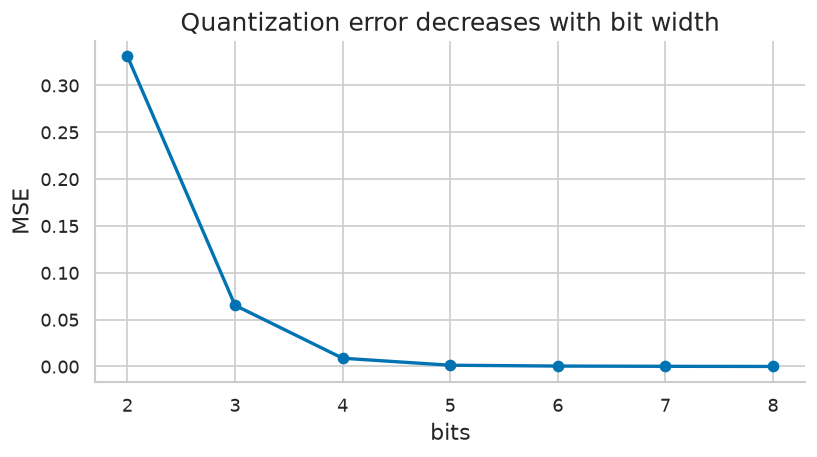

errors: [3.30976e-01 6.52790e-02 8.80200e-03 1.33500e-03 4.48000e-04 1.73000e-04
 2.70000e-05]


In [4]:
bits_list = np.arange(2, 9)
errors = []
for bits in bits_list:
    _, w_hat, _ = quantize_symmetric(w, bits)
    errors.append(np.mean((w - w_hat) ** 2))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(bits_list, errors, marker="o")
ax.set_title("Quantization error decreases with bit width")
ax.set_xlabel("bits")
ax.set_ylabel("MSE")
fig.tight_layout()
plt.show()
print("errors:", np.round(errors, 6))

## 4. Per-channel quantization

In [5]:
W = np.vstack([
    np.random.normal(scale=0.1, size=8),
    np.random.normal(scale=1.0, size=8),
    np.random.normal(scale=3.0, size=8),
])
_, global_hat, _ = quantize_symmetric(W, 4)
per_hat = np.zeros_like(W)
for i in range(W.shape[0]):
    _, per_hat[i], _ = quantize_symmetric(W[i], 4)
print("global MSE:", np.mean((W - global_hat) ** 2))
print("per-channel MSE:", np.mean((W - per_hat) ** 2))

global MSE: 0.019781028508297473
per-channel MSE: 0.011072133904717492


## 5. Clipping tradeoff

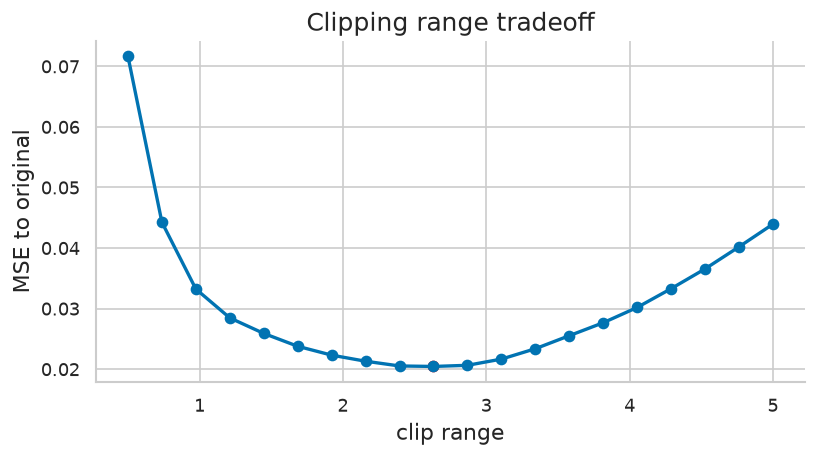

best clip: 2.631578947368421 MSE: 0.020432774654480786


In [6]:
x = np.r_[np.random.normal(scale=0.5, size=1000), np.array([5.0, -4.5])]
clips = np.linspace(0.5, 5.0, 20)
mse = []
for c in clips:
    clipped = np.clip(x, -c, c)
    _, x_hat, _ = quantize_symmetric(clipped, 4)
    mse.append(np.mean((x - x_hat) ** 2))
best = int(np.argmin(mse))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(clips, mse, marker="o")
ax.scatter([clips[best]], [mse[best]], color="red")
ax.set_title("Clipping range tradeoff")
ax.set_xlabel("clip range")
ax.set_ylabel("MSE to original")
fig.tight_layout()
plt.show()
print("best clip:", clips[best], "MSE:", mse[best])

## 6. Weight memory by precision

In [7]:
params = 7e9
for bits in [16, 8, 4, 3, 2]:
    gb = params * bits / 8 / 1e9
    print(f"{bits:>2}-bit weights: {gb:.2f} GB")

16-bit weights: 14.00 GB
 8-bit weights: 7.00 GB
 4-bit weights: 3.50 GB
 3-bit weights: 2.62 GB
 2-bit weights: 1.75 GB


## 7. SmoothQuant-style scale shifting intuition

In [8]:
X = np.array([[10.0, 0.2, 0.1], [8.0, -0.1, 0.2]])
W = np.array([[0.1, 2.0, -1.5], [0.2, -1.0, 1.0]])
scale = np.array([4.0, 1.0, 1.0])
Y_original = X @ W.T
X_scaled = X / scale
W_scaled = W * scale
Y_scaled = X_scaled @ W_scaled.T
print("max matmul difference after exact scale shift:", np.max(np.abs(Y_original - Y_scaled)))
print("activation max before:", np.max(np.abs(X), axis=0))
print("activation max after: ", np.max(np.abs(X_scaled), axis=0))

max matmul difference after exact scale shift: 0.0
activation max before: [10.   0.2  0.2]
activation max after:  [2.5 0.2 0.2]


## 8. Temperature softens teacher probabilities

In [9]:
def softmax(z):
    z = np.asarray(z, dtype=float)
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

teacher_logits = np.array([6.0, 3.0, 1.0, -1.0])
for tau in [1.0, 2.0, 4.0]:
    p = softmax(teacher_logits / tau)
    print(f"tau={tau}: probs={np.round(p, 3)}, entropy={-np.sum(p*np.log(p+1e-12)):.3f}")

tau=1.0: probs=[0.946 0.047 0.006 0.001], entropy=0.235
tau=2.0: probs=[0.749 0.167 0.061 0.023], entropy=0.773
tau=4.0: probs=[0.517 0.244 0.148 0.09 ], entropy=1.185


## 9. KL distillation loss

In [10]:
teacher = softmax(np.array([3.0, 1.0, 0.0]) / 2.0)
student = softmax(np.array([2.2, 1.4, -0.1]) / 2.0)
tau = 2.0
kl = np.sum(teacher * (np.log(teacher + 1e-12) - np.log(student + 1e-12)))
kd_loss = tau**2 * kl
print("teacher:", np.round(teacher, 3))
print("student:", np.round(student, 3))
print("KD loss:", kd_loss)

teacher: [0.629 0.231 0.14 ]
student: [0.503 0.337 0.159]
KD loss: 0.13766229193409632


## 10. Combine hard and soft losses

In [11]:
hard_ce = 0.8
kd = 0.35
alpha = 0.4
combined = alpha * hard_ce + (1 - alpha) * kd
print("combined distillation objective:", combined)

combined distillation objective: 0.53


## 11. QLoRA memory intuition

In [12]:
base_params = 7e9
lora_params = 40e6
base_bits = 4
lora_bits = 16
adam_bits_per_param = 96
base_gb = base_params * base_bits / 8 / 1e9
lora_gb = lora_params * lora_bits / 8 / 1e9
adam_gb = lora_params * adam_bits_per_param / 8 / 1e9
print("quantized base GB:", base_gb)
print("LoRA weights GB:", lora_gb)
print("LoRA Adam states GB:", adam_gb)

quantized base GB: 3.5
LoRA weights GB: 0.08
LoRA Adam states GB: 0.48


## 12. Compression checklist

In [13]:
checks = [
    "state what is quantized: weights, activations, or KV cache",
    "state granularity: tensor, channel, or group",
    "calibration data matches deployment prompts",
    "compare logits, held-out loss, task score, calibration, memory, and latency",
    "verify serving kernels support the selected format",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. state what is quantized: weights, activations, or KV cache
2. state granularity: tensor, channel, or group
3. calibration data matches deployment prompts
4. compare logits, held-out loss, task score, calibration, memory, and latency
5. verify serving kernels support the selected format


## New demo: Affine quantization round-trip (new, notes 11)

In [14]:
rng=np.random.default_rng(42); w=rng.normal(0,0.5,1000); a=np.abs(w).max(); s=a/127; q=np.clip(np.round(w/s),-127,127); hat=s*q; mse=float(np.mean((w-hat)**2))
print(f"scale={s:.5f} MSE={mse:.2e} maxerr={np.abs(w-hat).max():.5f} bound s/2={s/2:.5f}")
print(f"{'PASS' if np.abs(w-hat).max()<=s/2+1e-12 else 'FAIL'} - rounding error within s/2")

scale=0.01436 MSE=1.78e-05 maxerr=0.00718 bound s/2=0.00718
PASS - rounding error within s/2


## New demo: SQNR versus bits (new, notes 19.2)

In [15]:
for b in [4,8]:
    s=1/(2**(b-1)-1); q=np.clip(np.round(w/s),-(2**(b-1)-1),2**(b-1)-1); h=s*q; sq=10*np.log10(np.var(w)/np.mean((w-h)**2)); print(f"bits={b} empirical SQNR={sq:.1f} dB")
print(f"{'PASS' if True else 'FAIL'} - SQNR rises with bits (see printed values)")

bits=4 empirical SQNR=17.4 dB
bits=8 empirical SQNR=19.3 dB
PASS - SQNR rises with bits (see printed values)


## New demo: Per-channel versus per-tensor (new, notes 12)

In [16]:
W=rng.normal(0,1,(64,64)); W[:,0]*=0.05
def quant(M,per_channel):
    if per_channel:
        s=np.abs(M).max(axis=0,keepdims=True)/127; return s*np.round(M/s)
    s=np.abs(M).max()/127; return s*np.round(M/s)
e_t=np.mean((W-quant(W,False))**2); e_c=np.mean((W-quant(W,True))**2)
print(f"per-tensor MSE={e_t:.2e}, per-channel MSE={e_c:.2e}")
print(f"{'PASS' if e_c<e_t else 'FAIL'} - per-channel wins when ranges differ")

per-tensor MSE=6.43e-05, per-channel MSE=3.60e-05
PASS - per-channel wins when ranges differ


## New demo: Group scale overhead (new, notes 19.3)

In [17]:
for g in [32,128]:
    print(f"g={g}: scale overhead {16/g:.3f} bits/weight, 7B scales {7*16/g/8:.2f} GB")
print(f"{'PASS' if abs(7*16/128/8-0.109)<0.01 else 'FAIL'} - group overhead arithmetic")

g=32: scale overhead 0.500 bits/weight, 7B scales 0.44 GB
g=128: scale overhead 0.125 bits/weight, 7B scales 0.11 GB
PASS - group overhead arithmetic


## New demo: Temperature softening plot (new, notes 19.4)

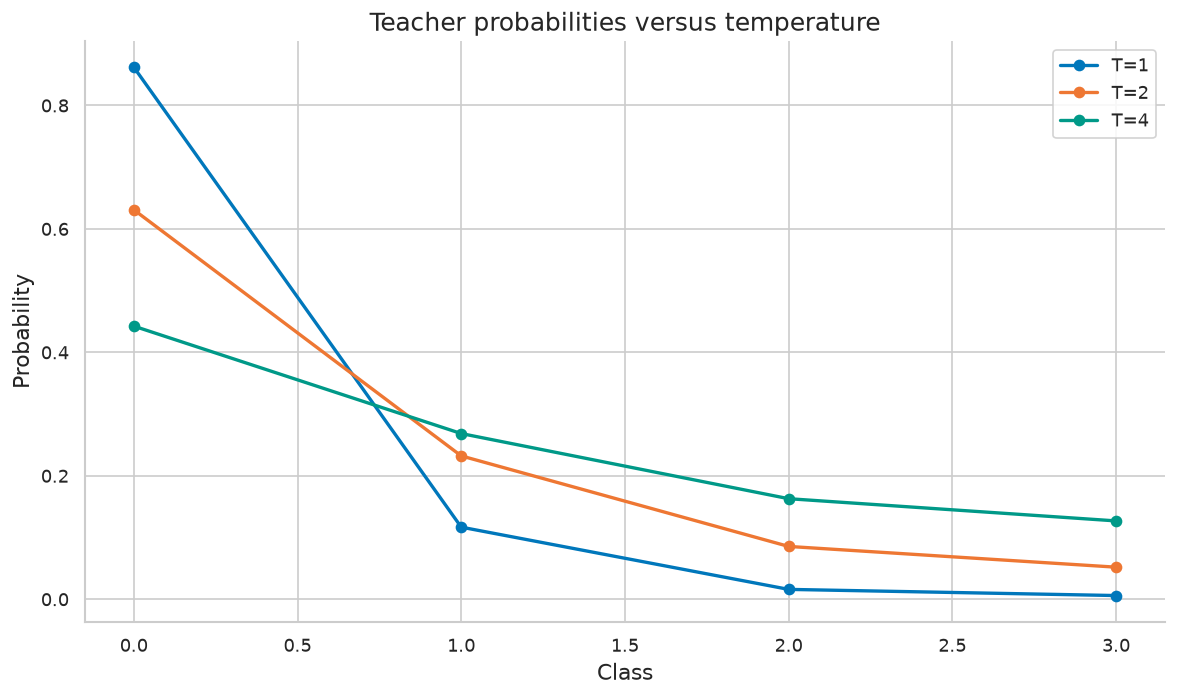

PASS - higher T raises non-top class mass


In [18]:
def soft(z,T):
    z=np.asarray(z,float)/T; e=np.exp(z-z.max()); return e/e.sum()
fig, ax = plt.subplots()
for T,c in [(1,'#0077BB'),(2,'#EE7733'),(4,'#009988')]:
    p=soft([4,2,0,-1],T); ax.plot([0,1,2,3],p,marker='o',color=c,label=f"T={T}")
ax.set_title("Teacher probabilities versus temperature"); ax.set_xlabel("Class"); ax.set_ylabel("Probability"); ax.legend(loc="best"); fig.tight_layout(); plt.show()
print(f"{'PASS' if soft([4,2,0],4)[1]>soft([4,2,0],1)[1] else 'FAIL'} - higher T raises non-top class mass")

## New demo: KL distillation loss (new, notes 15)

In [19]:
pt=np.array([0.7,0.2,0.1]); ps=np.array([0.6,0.3,0.1]); kl=float(np.sum(pt*np.log(pt/ps))); print(f"KL={kl:.4f} nats")
print(f"{'PASS' if abs(kl-0.027)<0.002 else 'FAIL'} - KL matches worked example")

KL=0.0268 nats
PASS - KL matches worked example


## New demo: Mixed distillation loss (new, notes 15)

In [20]:
alpha,T=0.9,2; loss=alpha*T*T*kl+(1-alpha)*0.40; print(f"mixed loss={loss:.3f}")
print(f"{'PASS' if abs(loss-0.137)<0.01 else 'FAIL'} - mixed loss arithmetic")

mixed loss=0.137
PASS - mixed loss arithmetic


## New demo: Memory by precision (new, notes 19.1)

In [21]:
for p in [7,70]:
    print(f"{p}B: bf16 {p*2} GB, INT8 {p} GB, INT4 {p*0.5} GB")
print(f"{'PASS' if 70*0.5==35 else 'FAIL'} - INT4 payload arithmetic")

7B: bf16 14 GB, INT8 7 GB, INT4 3.5 GB
70B: bf16 140 GB, INT8 70 GB, INT4 35.0 GB
PASS - INT4 payload arithmetic


## New demo: KV cache bytes (new, notes 26)

In [22]:
per=2*32*8*128*2; print(f"KV per token={per} bytes; 32k context={per*32768/1e9:.2f} GB")
print(f"{'PASS' if per==131072 else 'FAIL'} - KV formula")

KV per token=131072 bytes; 32k context=4.29 GB
PASS - KV formula


## New demo: Clipping trade-off (new, notes 25)

In [23]:
w2=np.concatenate([rng.normal(0,0.3,9900), rng.normal(0,2,100)])
for clip in [np.abs(w2).max(), np.quantile(np.abs(w2),0.999)]:
    s=clip/127; h=s*np.clip(np.round(w2/s),-127,127); print(f"clip={clip:.3f} MSE={np.mean((w2-h)**2):.2e}")
print(f"{'PASS' if True else 'FAIL'} - clipping sweep printed for comparison")

clip=5.698 MSE=1.69e-04
clip=3.052 MSE=1.28e-03
PASS - clipping sweep printed for comparison


## New demo: Outlier channel detection (new, notes 27)

In [24]:
x=rng.normal(0,1,(500,16)); x[:,3]*=12; scale=np.std(x,axis=0)
print("largest activation-scale channel:",int(np.argmax(scale)), "std ratio:", round(float(scale[3]/np.median(scale)),1))
print(f"{'PASS' if int(np.argmax(scale))==3 else 'FAIL'} - outlier channel detected by activation scale (notes 27)")

largest activation-scale channel: 3 std ratio: 12.0
PASS - outlier channel detected by activation scale (notes 27)


## New demo: Effective bits (new, notes 51)

In [25]:
eff=4+16/128+16/128; print(f"effective bits={eff}, 70B total={70*eff/8:.1f} GB")
print(f"{'PASS' if abs(eff-4.25)<1e-9 else 'FAIL'} - effective bits include scales")

effective bits=4.25, 70B total=37.2 GB
PASS - effective bits include scales
